*Notebook 02 of 12 in `notebooks/scripts_text/`. Parameters: `analysis/scripts_text/config.yaml`; decisions and run notes: `analysis/scripts_text/LOG.md`. The static page `site/scripts/index.html` is built from the same outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/scripts_text -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.static_figures import use_static_figures

from analysis.scripts_text import s02_layers as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 2 · Extracting text from the MovieSum markup

**What we do.** MovieSum marks up each screenplay: a `<scene>` holds a heading (`<stage_direction>`, e.g. INT.
DINER - DAY), action lines (`<scene_description>`), speaker cues (`<character>`), actors' directions
(`<parenthetical>`) and lines of speech (`<dialogue>`). We split every script into three layers:

1. **dialogue**: only what characters say;
2. **action**: only the descriptive prose of what we see;
3. **full**: everything except speaker cues, in script order.

**Why.** They answer different questions. Dialogue is how characters speak; action is how the writer tells the
story on the page. A word can be distinctive in one layer and invisible in the other. The primary analysis uses
dialogue because it is closest to what an audience hears.

**What it measures.** Which words sit in which part of the script, as MovieSum's tagger labelled them.

**What it misses.** The tagger isn't perfect: a cue it missed lands in the dialogue, a page header lands in the
action. Extraction is not resolution: a cue like "JULES (V.O.)" is just a string here. Speaker cues are set
aside, not lost: Step 3 uses them to find character names.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Table.** Parser sanity report on the 1,095 scripts. Nothing is dropped here; every problem is counted.

In [3]:
display(step.tables(res)["sanity"])

,check,scripts,share
0,parse error,0,0.000
1,empty dialogue layer,0,0.000
2,empty action layer,4,0.004
3,"fewer than 20 scene tags (flagged, kept)",44,0.040
4,fewer than 500 dialogue words (excluded from all comparisons: dialogue markup failed),8,0.007
5,no character cues,0,0.000


**Table.** Before and after, as counts, for three scripts: the raw markup's size, and what each layer keeps.

In [4]:
display(step.tables(res)["examples"])

,title,raw_chars,n_scenes,n_headings,n_cues,n_dialogue_lines,n_action_blocks,dialogue_words,action_words,full_words
26,The Godfather_1972,277108,225,225,905,946,554,12761,17296,31600
195,Pulp Fiction_1994,268564,85,85,1285,1341,432,16411,12170,29406
759,Inception_2010,274964,285,284,1233,1271,764,11560,13170,26267


**Private check.** The first 12 words of each layer for the same three scripts, to check that headings, dialogue and action land in the right layer. Notebook only, output cleared before commit (copyright).

In [5]:
display(step.private(res)["examples_text"])   # output cleared before commit

**Figure.** Words per script in each layer, for the unsuccessful (orange) and successful (blue) groups of definition (C) and the films in neither. If one group's scripts were much longer, raw counts would mislead; this is why every comparison uses rates per 10,000 words.

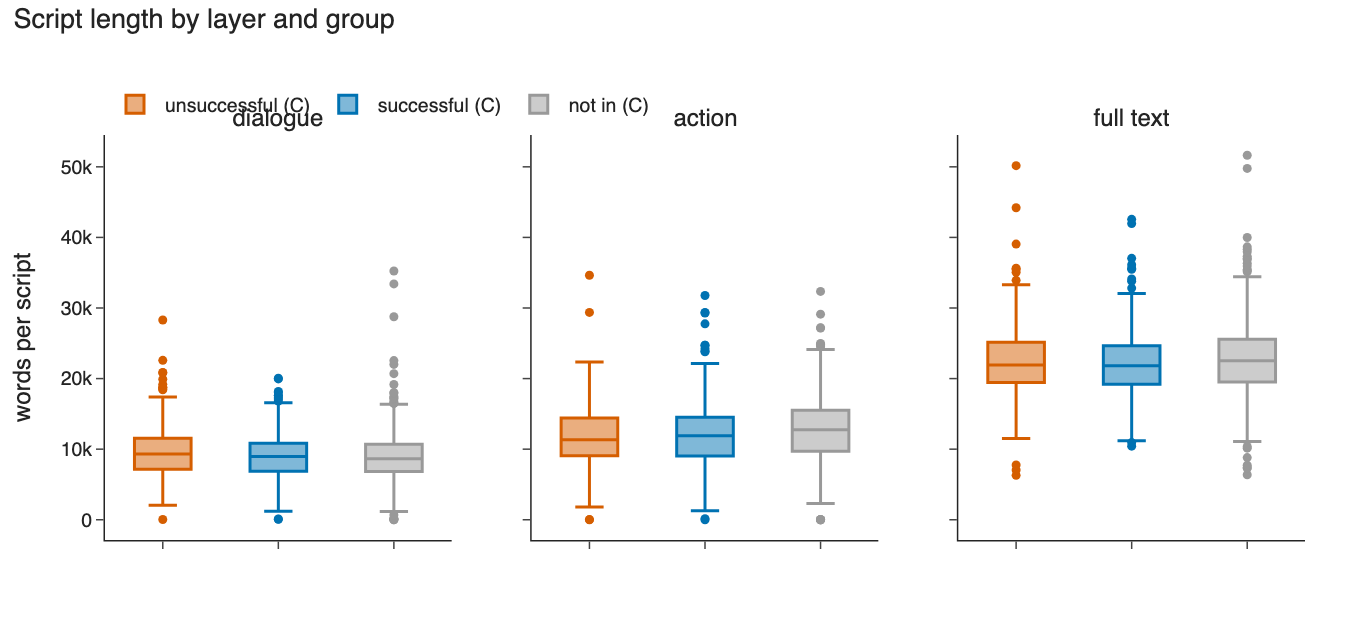

In [6]:
step.figures(res)["lengths"].show()

**Figure.** Dialogue's share of each script's words. The spread shows why the layers can disagree: some scripts are mostly talk, some mostly description.

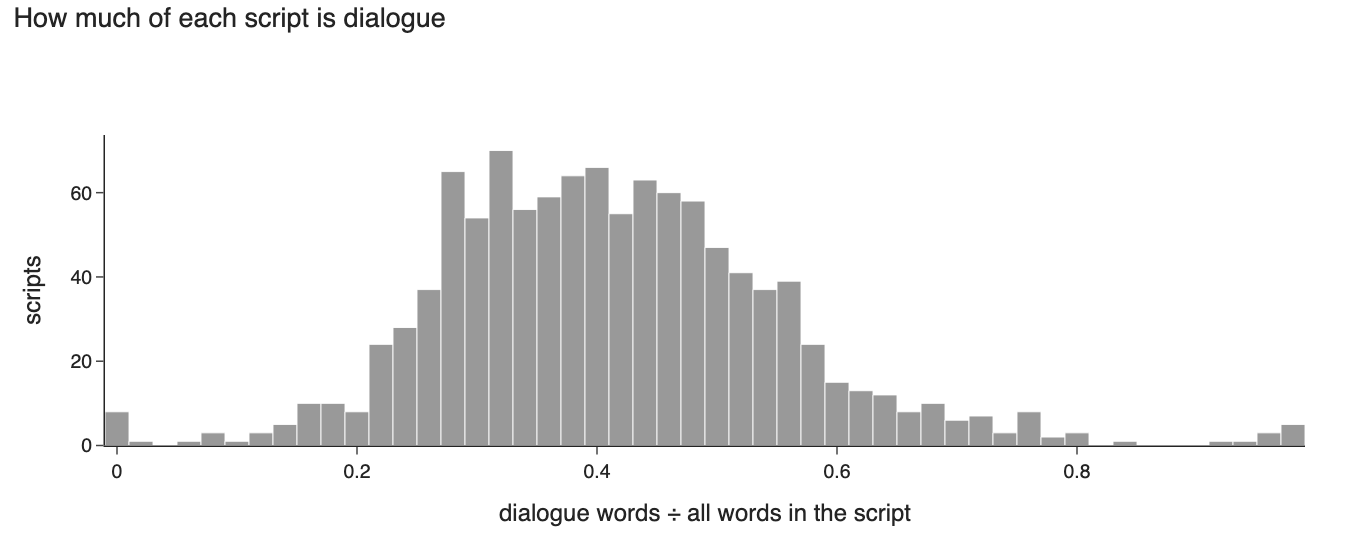

In [7]:
step.figures(res)["dialogue_share"].show()

**Table.** Median words and scenes per script, by group and definition.

In [8]:
display(step.tables(res)["lengths"])

,definition,group,scripts,median dialogue words,median action words,median full words,median scenes
0,A,low,67,10066,10821,22578,131
1,A,high,1028,8816,12285,22148,130
2,B,low,243,9182,11871,22481,132
3,B,high,306,8792,11413,21604,124
4,C,low,237,9315,11319,21936,131
5,C,high,292,8962,11901,21822,130


**Plain-language reading** (generated from the saved numbers):

In [9]:
display(Markdown(step.reading(res)))

All 1,095 scripts parse (0 errors). 0 have an empty dialogue layer and 4 an empty action layer. 44 have fewer than 20 scene tags, which usually means the scene markup is missing; they stay in, flagged, because the dialogue is still tagged. 8 scripts have fewer than 500 tagged dialogue words, which means the dialogue markup failed (Air Force One_1997, Carrie_1976, Casablanca_1942, It's a Wonderful Life_1946, Little Miss Sunshine_2006, Mary Poppins Returns_2018, Megamind_2010, The Matrix Reloaded_2003); they are excluded from every comparison from Step 5 on and counted here. The median script has 8,840 dialogue words, 12,170 action words and 22,180 words in all; dialogue is a median 40% of the words. Across all scripts that is 10,036,412 dialogue words and 13,560,605 action words.